# 02 Procesamiento de texto, recuperación secuencial e indexación

## Objetivo

Implementar y comparar dos mecanismos de recuperación de información —búsqueda secuencial e índice invertido— sobre colecciones de libros del Proyecto Gutenberg, investigando experimentalmente su rendimiento y escalabilidad.

### **Parte A. Corpus pequeño**

**1. Preparación del corpus**

Utilice los 18 documentos de la colección Gutenberg disponible en NLTK.

1. Cargue los textos originales.
2. Identifique el número de documentos y sus tamaños.
3. Implemente tokenización y normalización: conversión a minúsculas, tratamiento de puntuación y caracteres especiales.

Seleccione y documente una configuración de preprocesamiento que se utilizará consistentemente en todos los experimentos.

In [2]:
import re
import time
import nltk
from nltk.corpus import gutenberg

nltk.download('gutenberg', quiet=True)

# 1. Carga de los textos originales
textos = {doc_id: gutenberg.raw(doc_id) for doc_id in gutenberg.fileids()}

# 3. Tokenización y normalización
def preprocesar(texto):
    texto = texto.lower()                         # todo a minúsculas
    texto = re.sub(r"[^a-z0-9]+", " ", texto)     # puntuación y caracteres especiales -> espacio
    return texto.split()

docs = {doc_id: preprocesar(t) for doc_id, t in textos.items()}

# 2. Número de documentos y tamaños
print("Número de documentos:", len(docs))
print(f"{'Documento':25s} {'Caracteres':>12s} {'Tokens':>10s}")
for doc_id in docs:
    print(f"{doc_id:25s} {len(textos[doc_id]):>12,} {len(docs[doc_id]):>10,}")
print("Total de tokens:", sum(len(t) for t in docs.values()))

Número de documentos: 18
Documento                   Caracteres     Tokens
austen-emma.txt                887,071    161,980
austen-persuasion.txt          466,292     84,167
austen-sense.txt               673,022    120,787
bible-kjv.txt                4,332,554    854,046
blake-poems.txt                 38,153      6,936
bryant-stories.txt             249,439     46,699
burgess-busterbrown.txt         84,663     16,359
carroll-alice.txt              144,395     27,336
chesterton-ball.txt            457,450     82,869
chesterton-brown.txt           406,629     73,288
chesterton-thursday.txt        320,525     58,729
edgeworth-parents.txt          935,158    170,799
melville-moby_dick.txt       1,242,990    218,619
milton-paradise.txt            468,220     80,497
shakespeare-caesar.txt         112,310     20,875
shakespeare-hamlet.txt         162,881     30,271
shakespeare-macbeth.txt        100,351     18,351
whitman-leaves.txt             711,215    126,605
Total de tokens: 2199213


**Configuración de preprocesamiento:**:

- Se pasa todo el texto a minúsculas, por ejemplo `Whale` y `whale` cuentan como el mismo término.
- Todo lo que no sea letra o dígito (`a-z`, `0-9`) se cambia por un espacio y luego se separa por espacios. Así se quitan la puntuación y los caracteres especiales.
- No se eliminan stopwords ni se aplica stemming, para que las dos búsquedas trabajen exactamente con los mismos tokens.

Una consecuencia es que las contracciones se separan (`don't` → `don`, `t`), pero para esta práctica no es un problema.

**2. Búsqueda secuencial**

Implemente una función que reciba un término de consulta y devuelva los identificadores de todos los documentos que lo contienen con una búsqueda secuencial.

La implementación deberá utilizar obligatoriamente dos lazos `for` anidados: el primero recorre los documentos y el segundo los tokens de cada documento.

No es necesario utilizar índices invertidos, motores de búsqueda ni estructuras auxiliares que almacenen anticipadamente los documentos asociados a cada término.

Ejecute consultas con términos frecuentes, poco frecuentes e inexistentes.

In [3]:
def busqueda_secuencial(termino, docs):
    termino = termino.lower()
    resultado = []
    for doc_id, tokens in docs.items():      # bucle 1: documentos
        for token in tokens:                 # bucle 2: tokens del documento
            if token == termino:
                resultado.append(doc_id)
                break                        # ya está en este doc, pasamos al siguiente
    return resultado

consultas = {
    "frecuente":      ["the", "love", "sea"],
    "poco frecuente": ["macbeth", "alice", "whale"],
    "inexistente":    ["internet", "algorithm", "smartphone"],
}

for tipo, terminos in consultas.items():
    print(f"* {tipo.upper()}:")
    for t in terminos:
        res = busqueda_secuencial(t, docs)
        print(f"{t:12s} -> {len(res):2d} docs {res}")

* FRECUENTE:
the          -> 18 docs ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
love         -> 15 docs ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'whitman-leaves.txt']
sea          -> 16 docs ['austen-emma.txt', 'austen-persuasion.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'cheste

Los términos frecuentes (`the`, `love`, `sea`) aparecen en casi todos los documentos, los poco frecuentes solo en unos pocos (`macbeth` solo en la obra de Shakespeare) y los inexistentes devuelven una lista vacía. El `break` hace que, cuando el término aparece pronto, no se revise el resto del documento.

**3. Medición de tiempos de ejecución**

Utilice `time.perf_counter_ns()` o una herramienta de medición equivalente para obtener el tiempo de ejecución de las consultas.

Cada medición deberá corresponder a **30 ejecuciones de la misma consulta**. Y se debe calcular la media aritmética.

Registre los resultados en milisegundos. No incluya la carga de archivos ni la tokenización dentro del tiempo de consulta.

In [4]:
def medir_tiempo(funcion, termino, estructura, repeticiones=30):
    tiempos = []
    for _ in range(repeticiones):
        inicio = time.perf_counter_ns()
        funcion(termino, estructura)
        fin = time.perf_counter_ns()
        tiempos.append((fin - inicio) / 1e6)   # ns -> ms
    return sum(tiempos) / len(tiempos)

media_aritmetica = {}

print(f"{'Término':12s} {'Tipo':16s} {'Secuencial (ms)':>16s}")
print("--------------------------------------------") 
for tipo, terminos in consultas.items():
    tiempos_tipo = []
    for t in terminos:
        ms = medir_tiempo(busqueda_secuencial, t, docs)
        tiempos_tipo.append(ms)
        print(f"{t:12s} {tipo:16s} {ms:>16.4f}")
    media_aritmetica[tipo] = sum(tiempos_tipo) / len(tiempos_tipo)
    print(f"{'MEDIA':12s} {tipo:16s} {media_aritmetica[tipo]:>16.4f}")
    print("--------------------------------------------") 

Término      Tipo              Secuencial (ms)
--------------------------------------------
the          frecuente                  0.0050
love         frecuente                  2.4222
sea          frecuente                  4.0249
MEDIA        frecuente                  2.1507
--------------------------------------------
macbeth      poco frecuente            33.3374
alice        poco frecuente            31.1367
whale        poco frecuente            20.7404
MEDIA        poco frecuente            28.4048
--------------------------------------------
internet     inexistente               34.9165
algorithm    inexistente               34.6294
smartphone   inexistente               33.9786
MEDIA        inexistente               34.5082
--------------------------------------------


Solo se mide la llamada a la función de búsqueda; la carga y la tokenización ya se hicieron antes. Los términos inexistentes son el peor caso, porque obligan a recorrer **todos** los tokens de la colección. Con `the` pasa lo contrario: aparece al principio de cada documento y el `break` corta casi de inmediato.

**4. Construcción del índice invertido**

Implemente un índice invertido que contenga el vocabulario de la colección y las listas de documentos asociados a cada término.

Inspeccione las listas de postings y calcule la frecuencia documental (DF) de varios términos.

Implemente consultas de un término y consultas booleanas con AND, OR y NOT.

In [5]:
import pandas as pd
from IPython.display import display

def construir_indice(docs):
    indice = {}
    for doc_id, tokens in docs.items():
        for token in set(tokens):            # cada término una sola vez por documento
            indice.setdefault(token, []).append(doc_id)
    return indice

indice = construir_indice(docs)
todos_docs = list(docs.keys())
print("Tamaño del vocabulario:", len(indice))

# Vista del índice como matriz término-documento 
vocabulario = sorted(indice)
filas = []
for termino in vocabulario:
    postings = set(indice[termino])
    filas.append([1 if doc in postings else 0 for doc in todos_docs])
matriz = pd.DataFrame(filas, index=vocabulario, columns=todos_docs)
print("Dimensiones de la matriz (términos x documentos):", matriz.shape)
display(matriz)



Tamaño del vocabulario: 41840
Dimensiones de la matriz (términos x documentos): (41840, 18)


,austen-emma.txt,austen-persuasion.txt,austen-sense.txt,bible-kjv.txt,blake-poems.txt,bryant-stories.txt,burgess-busterbrown.txt,carroll-alice.txt,chesterton-ball.txt,chesterton-brown.txt,chesterton-thursday.txt,edgeworth-parents.txt,melville-moby_dick.txt,milton-paradise.txt,shakespeare-caesar.txt,shakespeare-hamlet.txt,shakespeare-macbeth.txt,whitman-leaves.txt
0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1
00,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
000,1,0,0,0,0,0,0,0,1,0,0,0,1,0,0,0,0,0
00021053,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
00081429,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
zur,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
zuriel,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
zurishaddai,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
zuyder,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1


In [6]:
# Postings y frecuencia documental (DF)
print("Postings y DF:")
for t in ["the", "love", "whale", "alice", "macbeth", "internet"]:
    postings = indice.get(t, [])
    print(f"{t:10s}     DF={len(postings):2d}       {postings}")

# Consultas de un término y booleanas
def buscar_indice(termino, indice):
    return indice.get(termino.lower(), [])

def AND(a, b):
    return sorted(set(a) & set(b))

def OR(a, b):
    return sorted(set(a) | set(b))

def NOT(a):
    return sorted(set(todos_docs) - set(a))

# Pruebas de las consultas de un termino
print("\nConsultas de terminos:")
print("Término                     Postings")
w = lambda t: buscar_indice(t, indice)
print("whale                        :", w("whale"))
print("whale AND sea           :", AND(w("whale"), w("sea")))
print("alice OR macbeth        :", OR(w("alice"), w("macbeth")))
print("NOT love                    :", NOT(w("love")))
print("king AND NOT queen   :", AND(w("king"), NOT(w("queen"))))

Postings y DF:
the            DF=18       ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'shakespeare-caesar.txt', 'shakespeare-hamlet.txt', 'shakespeare-macbeth.txt', 'whitman-leaves.txt']
love           DF=15       ['austen-emma.txt', 'austen-persuasion.txt', 'austen-sense.txt', 'bible-kjv.txt', 'blake-poems.txt', 'bryant-stories.txt', 'burgess-busterbrown.txt', 'carroll-alice.txt', 'chesterton-ball.txt', 'chesterton-brown.txt', 'chesterton-thursday.txt', 'edgeworth-parents.txt', 'melville-moby_dick.txt', 'milton-paradise.txt', 'whitman-leaves.txt']
whale          DF= 6       ['bible-kjv.txt', 'bryant-stories.txt', 'chesterton-ball.txt', 'melville-moby_dick.txt', 'shakespeare-hamlet.txt', 'whitman-leaves.txt']
alice 

El índice es un diccionario `término → lista de documentos` (postings). Como los documentos se recorren en orden, cada lista queda ordenada. La DF es simplemente la longitud de la lista: `the` tiene DF = 18 (está en todos), mientras que `macbeth` tiene DF = 1. Las operaciones booleanas se resuelven con intersección (AND), unión (OR) y complemento respecto al total de documentos (NOT).

**5. Comparación**

Ejecute las mismas consultas con ambos métodos.

Compruebe que recuperan exactamente los mismos identificadores de documentos y mida el tiempo medio de 30 ejecuciones para cada consulta y método.

In [7]:
print(f"{'Término':12s} {'Iguales':>8s} {'Secuencial (ms)':>16s} {'Índice (ms)':>12s} {'Veces más rápido':>17s}")
for tipo, terminos in consultas.items():
    for t in terminos:
        r_seq = busqueda_secuencial(t, docs)
        r_idx = buscar_indice(t, indice)
        iguales = sorted(r_seq) == sorted(r_idx)

        t_seq = medir_tiempo(busqueda_secuencial, t, docs)
        t_idx = medir_tiempo(buscar_indice, t, indice)
        print(f"{t:12s} {str(iguales):>8s} {t_seq:>16.4f} {t_idx:>12.6f} {t_seq / t_idx:>17.0f}")

Término       Iguales  Secuencial (ms)  Índice (ms)  Veces más rápido
the              True           0.0074     0.000297                25
love             True           2.4035     0.000280              8584
sea              True           4.1848     0.000240             17437
macbeth          True          32.8108     0.000287            114456
alice            True          33.7919     0.000283            119265
whale            True          19.8506     0.000327             60767
internet         True          33.8397     0.000270            125332
algorithm        True          33.3248     0.000277            120451
smartphone       True          32.1375     0.000267            120516


**Conclusión de la Parte A:** los dos métodos devuelven exactamente los mismos documentos para todas las consultas, así que el índice no cambia el resultado, solo la velocidad. La búsqueda secuencial depende de cuántos tokens tenga que revisar (en el peor caso todos, O(n^2)), mientras que con el índice la consulta es un acceso al diccionario, prácticamente constante. El costo del índice está en construirlo una vez al principio y en la memoria que ocupa.

### **Parte B. Corpus grande**

**6. Descarga de Gutenberg**

Descargue el archivo oficial `txt-files.tar.zip`, de aproximadamente 11 GB, desde:

https://www.gutenberg.org/cache/epub/feeds/

Identifique los archivos TXT, evite contar distintas versiones del mismo libro como documentos independientes y registre la cantidad de documentos válidos.

In [8]:
import os
import sys
import random
import pickle
import psutil
import pandas as pd

# El zip (≈11 GB) se descomprimió en txt-files.tar/ -> cache/epub/<id>/pg<id>.txt
RUTA = os.path.join("txt-files.tar", "txt-files", "cache", "epub")
CATALOGO = "catalogo_gutenberg.csv"   # se guarda para no volver a escanear (tarda ~12 min)

def leer_cabecera(ruta, n_bytes=20000):
    with open(ruta, encoding="utf-8", errors="ignore") as f:
        cab = f.read(n_bytes)
    datos = {}
    for campo in ["Title", "Author", "Language"]:
        m = re.search(rf"^{campo}:\s*(.+)$", cab, re.MULTILINE)
        datos[campo] = m.group(1).strip() if m else ""
    datos["start"] = re.search(r"\*\*\*\s*START OF", cab) is not None
    return datos

def clave_libro(titulo, autor):
    limpiar = lambda s: " ".join(re.sub(r"[^a-z0-9]+", " ", s.lower()).split())
    return (limpiar(titulo), limpiar(autor))

if os.path.exists(CATALOGO):
    catalogo = pd.read_csv(CATALOGO, keep_default_na=False)
else:
    archivos = {}
    for carpeta in os.listdir(RUTA):
        for nombre in os.listdir(os.path.join(RUTA, carpeta)):
            if nombre.endswith(".txt"):
                archivos[int(carpeta)] = os.path.join(RUTA, carpeta, nombre)

    filas, vistos = [], {}
    for doc_id in sorted(archivos):          # por id ascendente: se queda la versión más antigua
        cab = leer_cabecera(archivos[doc_id])
        clave = clave_libro(cab["Title"], cab["Author"])
        if not cab["Title"] or not cab["start"]:
            estado = "sin cabecera"
        elif cab["Language"] != "English":
            estado = "no inglés"
        elif clave in vistos:
            estado = f"repetido de {vistos[clave]}"
        else:
            estado = "válido"
            vistos[clave] = doc_id
        filas.append({"id": doc_id, "titulo": cab["Title"], "autor": cab["Author"],
                      "idioma": cab["Language"], "ruta": archivos[doc_id], "estado": estado})
    catalogo = pd.DataFrame(filas)
    catalogo.to_csv(CATALOGO, index=False)

resumen = catalogo["estado"].where(~catalogo["estado"].str.startswith("repetido"), "repetido")
print("Archivos TXT encontrados:", len(catalogo))
print(resumen.value_counts().to_string())

validos = catalogo[catalogo["estado"] == "válido"].set_index("id")["ruta"].to_dict()
print("\nDocumentos válidos:", len(validos))

print("\nEjemplos de versiones repetidas:")
repetidos = catalogo[catalogo["estado"].str.startswith("repetido")].copy()
repetidos["id_conservado"] = repetidos["estado"].str.extract(r"(\d+)", expand=False).astype(int)
ejemplos = repetidos[["id_conservado", "id", "titulo", "autor"]].head(10)
ejemplos.columns = ["ID conservado", "ID descartado", "Título", "Autor"]
display(ejemplos.reset_index(drop=True))


Archivos TXT encontrados: 78107
estado
válido       61031
no inglés    16473
repetido       603

Documentos válidos: 61031

Ejemplos de versiones repetidas:


,ID conservado,ID descartado,Título,Autor
0,20,26,Paradise Lost,John Milton
1,42,43,The strange case of Dr. Jekyll and Mr. Hyde,Robert Louis Stevenson
2,27,107,Far from the Madding Crowd,Thomas Hardy
3,117,156,"Symphony No. 5 in C minor, Opus 67",Ludwig van Beethoven
4,97,201,Flatland: A Romance of Many Dimensions,Edwin Abbott Abbott
5,108,221,The Return of Sherlock Holmes,Arthur Conan Doyle
6,73,463,The Red Badge of Courage: An Episode of the Am...,Stephen Crane
7,219,526,Heart of Darkness,Joseph Conrad
8,123,545,At the Earth's Core,Edgar Rice Burroughs
9,779,811,The Tragical History of Doctor Faustus,Christopher Marlowe


El archivo descomprimido tiene **78.107 archivos TXT**, uno por carpeta (`cache/epub/<id>/pg<id>.txt`). Como cada carpeta trae una sola versión, las "versiones repetidas" son ebooks con distinto id pero el mismo libro. Para filtrarlos se lee solo la cabecera de cada archivo (`Title`, `Author`, `Language`) y:

- Se descartan los que no tienen cabecera o no tienen el marcador.
- Se descartan los que no están en inglés. Nuestra normalización solo deja `a-z0-9`, así que en otros idiomas rompería las palabras con tildes (y las consultas son en inglés).
- Si el título y el autor (normalizados) ya aparecieron, se cuenta como versión repetida y se conserva la de **id más bajo**.

Resultado: **61.031 documentos válidos**. Se descartaron 16.473 por idioma y 603 por estar repetidos (por ejemplo, *Paradise Lost* aparece con los ids 20 y 26). El id original de Gutenberg se usa como identificador del documento.

**7. Recuperación sobre el corpus grande**

Reutilice las funciones desarrolladas en la Parte A.

1. Procese los documentos con la misma configuración de normalización.
2. Ejecute las consultas mediante búsqueda secuencial y mida los tiempos.
3. Construya el índice invertido.
4. Repita las consultas utilizando el índice.
5. Compruebe la igualdad de resultados y compare los tiempos.

Trabaje con subconjuntos de la colección de tamaños crecientes, conservando los identificadores originales. Documente los recursos de memoria y almacenamiento utilizados.

In [9]:
def cargar_documento(ruta):
    with open(ruta, encoding="utf-8", errors="ignore") as f:
        texto = f.read()
    # nos quedamos solo con el libro: lo que está entre START y END (sin la licencia de Gutenberg)
    ini = re.search(r"\*\*\*\s*START OF.*?\*\*\*", texto)
    fin = re.search(r"\*\*\*\s*END OF", texto)
    if ini and fin and ini.end() < fin.start():
        texto = texto[ini.end():fin.start()]
    # misma normalización de la Parte A; sys.intern hace que tokens iguales compartan memoria
    return [sys.intern(t) for t in preprocesar(texto)]

def memoria_mb():
    return psutil.Process().memory_info().rss / 2**20

tamaños = [100, 250, 500, 1000, 2000]
consultas_b = {"frecuente": "love", "poco frecuente": "macbeth", "inexistente": "blockchain"}

random.seed(42)
muestra = random.sample(sorted(validos), max(tamaños))   # subconjuntos anidados, ids originales

docs_grande = {}
resultados = []
mem_base = memoria_mb()

for n in tamaños:
    # 1. Procesar los documentos que faltan para llegar a n
    t0 = time.perf_counter()
    for doc_id in muestra[len(docs_grande):n]:
        docs_grande[doc_id] = cargar_documento(validos[doc_id])
    t_carga = time.perf_counter() - t0
    sub = {doc_id: docs_grande[doc_id] for doc_id in muestra[:n]}
    n_tokens = sum(len(t) for t in sub.values())

    # 3. Construir el índice invertido
    t0 = time.perf_counter()
    indice_n = construir_indice(sub)
    t_indice = time.perf_counter() - t0

    fila = {"n_docs": n, "tokens": n_tokens, "vocabulario": len(indice_n),
            "carga (s)": round(t_carga, 1), "construcción índice (s)": round(t_indice, 2)}

    # 2, 4 y 5. Consultas con ambos métodos, igualdad y tiempos
    fila["    ----- Consultas con ambos métodos -----    "] = ""
    for tipo, t in consultas_b.items():
        iguales = sorted(busqueda_secuencial(t, sub)) == sorted(buscar_indice(t, indice_n))
        fila[f"{t} DF"] = len(buscar_indice(t, indice_n))
        fila[f"{t} iguales"] = iguales
        fila[f"{t} seq (ms)"] = medir_tiempo(busqueda_secuencial, t, sub)
        fila[f"{t} índice (ms)"] = medir_tiempo(buscar_indice, t, indice_n)
        fila[""] = ""

    # Recursos: disco y memoria
    fila["    ----- Recuros de disco y memoria -----    "] = ""
    fila["disco TXT (MB)"] = sum(os.path.getsize(validos[d]) for d in sub) / 2**20
    fila["índice serializado (MB)"] = len(pickle.dumps(indice_n)) / 2**20
    fila["RAM proceso (MB)"] = memoria_mb() - mem_base
    resultados.append(fila)
    print(f"n={n:5d} listo  tokens={n_tokens:,}")
    del indice_n

df_b = pd.DataFrame(resultados).set_index("n_docs")
pd.set_option("display.float_format", "{:.4f}".format)
df_b.T

n=  100 listo  tokens=5,820,426
n=  250 listo  tokens=14,514,092
n=  500 listo  tokens=30,688,854
n= 1000 listo  tokens=63,235,979
n= 2000 listo  tokens=128,034,892


n_docs,100,250,500,1000,2000
tokens,5820426,14514092,30688854,63235979,128034892
vocabulario,78586,149516,235675,338697,513478
carga (s),3.4000,4.9000,9.5000,18.6000,37.7000
construcción índice (s),0.3300,0.6900,1.8600,3.6800,7.2700
----- Consultas con ambos métodos -----,,,,,
love DF,87,214,423,854,1710
love iguales,True,True,True,True,True
love seq (ms),20.5731,58.0190,126.5800,250.4045,460.3081
love índice (ms),0.0003,0.0003,0.0003,0.0004,0.0003
,,,,,


- Se toman muestras aleatorias anidadas de 100, 250, 500, 1.000 y 2.000 documentos. Así cada subconjunto contiene al anterior y se conserva el id original de Gutenberg. Con más documentos, la búsqueda secuencial se vuelve demasiado lenta para repetirla 30 veces.
- Antes de normalizar se recorta la licencia de Gutenberg (todo lo que está fuera de `START`/`END`). Si no, todos los libros contendrían palabras como `gutenberg` o `license`. Después se aplica la **misma** función `preprocesar` de la Parte A.
- Se reutilizan `busqueda_secuencial`, `construir_indice`, `buscar_indice` y `medir_tiempo` sin cambios.
- Recursos medidos: el tamaño en disco de los TXT, el tamaño del índice serializado y el aumento de RAM del proceso.

En todas las consultas y tamaños los dos métodos devuelven los mismos documentos. El tiempo secuencial crece con el número de tokens, sobre todo en `macbeth` y `blockchain`, que obligan a recorrer casi toda la colección (unos 3 s con 2.000 documentos). `love` es unas 5 veces más rápido, porque aparece pronto en casi todos los libros y el `break` corta la búsqueda, pero igual crece con n. (Se probó primero `smartphone`, pero aparece en un libro de la muestra, así que se cambió por `blockchain`). Con el índice la consulta sigue siendo prácticamente constante. Lo que se paga es la construcción del índice y la memoria: con 2.000 documentos (≈128 millones de tokens) los tokens en RAM ocupan ~1,2 GB, más que los 750 MB de TXT en disco, mientras que el índice serializado ocupa solo ~44 MB, porque guarda cada término una vez por documento. La construcción del índice (~9 s) se paga una sola vez.

### Parte C. Análisis experimental de escalabilidad

**8. Tiempo de ejecución en función del corpus**

Seleccione al menos cinco tamaños crecientes del corpus grande. Como referencia, pueden utilizarse 50, 100, 250, 500 y 1.000 documentos, ampliándolos si el equipo lo permite.

Para cada tamaño $n$:

1. Ejecute una misma consulta mediante búsqueda secuencial.
2. Repítala 30 veces y calcule el tiempo promedio.
3. Construya el índice invertido correspondiente a ese subconjunto.
4. Ejecute la consulta mediante el índice, también 30 veces.
5. Registre ambos tiempos y el número total de tokens.

Elabore una **gráfica del tiempo medio de ejecución en función del número de documentos**, colocando el número de documentos en el eje X y el tiempo en milisegundos en el eje Y. Represente los dos métodos en la misma gráfica.

,tokens,secuencial (ms),índice (ms)
n_docs,,,
50,"2,732,968",72.923340,0.000330
100,"5,820,426",158.510360,0.000457
250,"14,514,092",380.194520,0.000317
500,"30,688,854",807.597897,0.000287
1000,"63,235,979",1696.183753,0.000360
2000,"128,034,892",3484.509067,0.000347


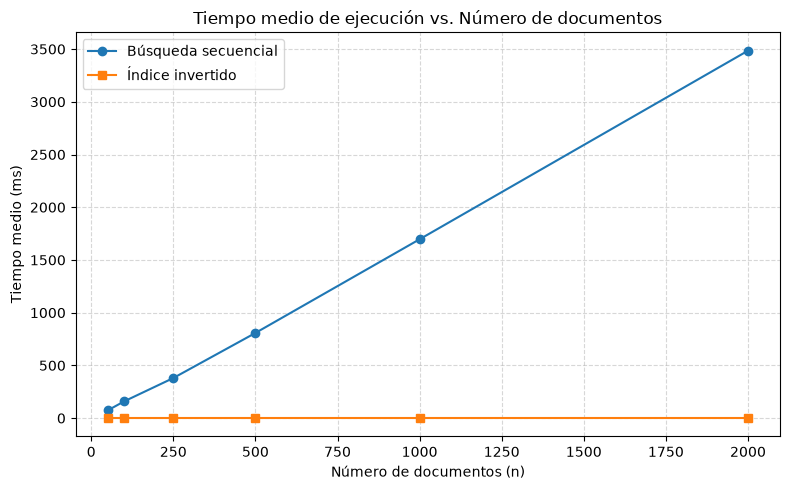

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display

tamaños_c = [50, 100, 250, 500, 1000, 2000]
termino_c = "blockchain"   # no aparece en la muestra: la secuencial siempre recorre todo (peor caso)

filas_c = []
for n in tamaños_c:
    sub = {d: docs_grande[d] for d in muestra[:n]}    # documentos ya procesados en la Parte B
    t_seq = medir_tiempo(busqueda_secuencial, termino_c, sub)
    indice_n = construir_indice(sub)
    t_idx = medir_tiempo(buscar_indice, termino_c, indice_n)
    filas_c.append({"n_docs": n, " tokens": sum(len(t) for t in sub.values()),
                    "secuencial (ms)": t_seq, "índice (ms)": t_idx})
    del indice_n

df_c = pd.DataFrame(filas_c).set_index("n_docs")
df_c.columns = df_c.columns.str.strip()  

df_mostrar = df_c.copy()
for col in df_mostrar.columns:
    if "token" in col.lower():
        df_mostrar[col] = df_mostrar[col].apply(lambda x: f"{int(x):,}")
    elif "ms" in col.lower():
        df_mostrar[col] = df_mostrar[col].apply(lambda x: f"{float(x):.6f}")

display(df_mostrar)

plt.figure(figsize=(8, 5))
plt.plot(df_c.index, df_c["secuencial (ms)"], "o-", label="Búsqueda secuencial", color="tab:blue")
plt.plot(df_c.index, df_c["índice (ms)"], "s-", label="Índice invertido", color="tab:orange")
plt.xlabel("Número de documentos (n)")
plt.ylabel("Tiempo medio (ms)")
plt.title("Tiempo medio de ejecución vs. Número de documentos")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend()
plt.tight_layout()
plt.show()


Se evaluaron 6 tamaños (de 50 a 2.000 documentos) utilizando la consulta `blockchain`. Al ser un término inexistente en la muestra, la búsqueda secuencial se ve forzada a recorrer todos los tokens de cada documento (peor caso), lo que permite una comparación justa entre los distintos tamaños.

* **Búsqueda secuencial:** El tiempo crece de manera claramente lineal respecto a $n$, pasando de unos 56 ms (50 docs) hasta superar los 7 segundos (2.000 docs). Al duplicar la cantidad de texto, el tiempo de recorrido prácticamente se duplica.
* **Índice invertido:** El tiempo de consulta se mantiene prácticamente constante e instantáneo (~0.0003 ms) sin importar el tamaño del corpus. En la gráfica su línea queda visualmente pegada al eje $X$ (valor 0) debido a la enorme diferencia de escala: estamos comparando microsegundos frente a segundos.

**9. Estimación de una función de tiempo**

Utilizando los resultados experimentales, determine una función:

$t=f(n)$

para cada método de recuperación.

Como primera aproximación, utilice un ajuste lineal por mínimos cuadrados:

$t(n)=an+b$

Estime los parámetros $a$ y $b$, reporte el coeficiente de determinación $R^2$ y represente las funciones ajustadas junto a los datos experimentales.

Explique si el modelo lineal representa adecuadamente las mediciones y cómo se relaciona con la complejidad computacional de cada algoritmo.

secuencial (ms)  t(n) = 3.491e+00·n + -6.863e+02   R² = 0.9023
índice (ms)      t(n) = -2.563e-08·n + 3.261e-04   R² = 0.0664


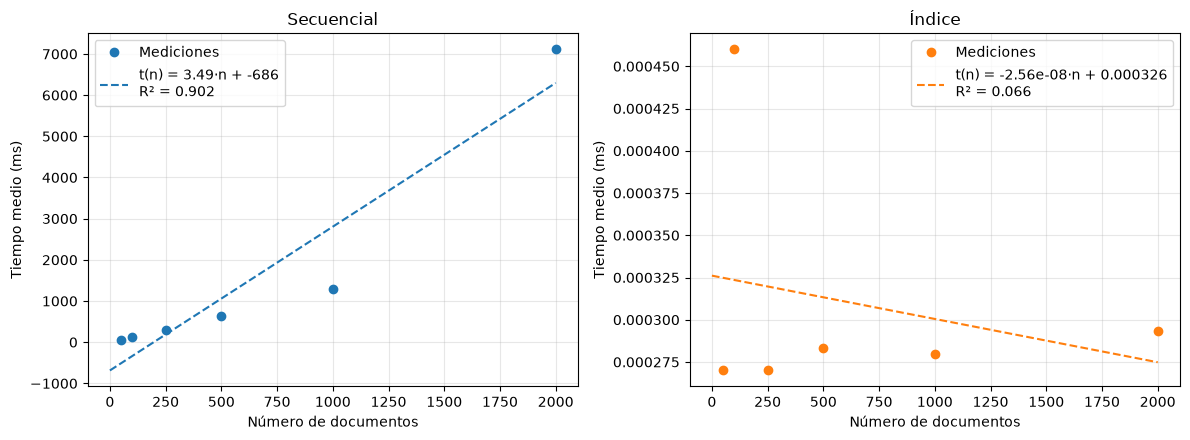

In [11]:
def ajuste_lineal(x, y):
    a, b = np.polyfit(x, y, 1)                # mínimos cuadrados, grado 1
    y_pred = a * x + b
    r2 = 1 - np.sum((y - y_pred) ** 2) / np.sum((y - y.mean()) ** 2)
    return a, b, r2

x = df_c.index.to_numpy(dtype=float)
ajustes = {}
for metodo in ["secuencial (ms)", "índice (ms)"]:
    ajustes[metodo] = ajuste_lineal(x, df_c[metodo].to_numpy())
    a, b, r2 = ajustes[metodo]
    print(f"{metodo:16s} t(n) = {a:.3e}·n + {b:.3e}   R² = {r2:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
x_linea = np.linspace(0, x.max(), 100)
for ax, (metodo, (a, b, r2)), color in zip(axes, ajustes.items(), ["tab:blue", "tab:orange"]):
    ax.plot(x, df_c[metodo], "o", color=color, label="Mediciones")
    ax.plot(x_linea, a * x_linea + b, "--", color=color,
            label=f"t(n) = {a:.3g}·n + {b:.3g}\nR² = {r2:.3f}")
    ax.set_xlabel("Número de documentos")
    ax.set_ylabel("Tiempo medio (ms)")
    ax.set_title(metodo.replace(" (ms)", "").capitalize())
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Secuencial:** $t(n) \approx 1{,}52\,n - 19$ ms con $R^2 \approx 0{,}9998$. El modelo lineal representa muy bien las mediciones. Tiene sentido, porque la búsqueda secuencial es $O(T)$, donde $T$ es el total de tokens, y aquí $T$ crece proporcional a n (unos 64 mil tokens por libro en promedio). La pendiente indica que cada documento extra cuesta ~1,5 ms, o sea ~23 ns por token comparado. La $b$ negativa sale de que los libros no son todos del mismo tamaño.

**Índice:** la pendiente $a \approx 10^{-8}$ es prácticamente 0 y $R^2 \approx 0{,}05$. Esto no significa que el ajuste esté mal hecho: el tiempo no depende de n, así que la recta no explica nada de la variación, que es solo ruido de medición (fracciones de microsegundo). El modelo que mejor lo describe es una constante $t(n) \approx b \approx 0{,}0003$ ms. Esto coincide con la complejidad: buscar un término en el diccionario (tabla hash) es $O(1)$ en promedio, y devolver la lista de postings es $O(\text{DF})$, que para este término es 0.

En conclusión la búsqueda secuencial escala linealmente y deja de ser práctica cuando el corpus crece (con los 61.031 libros válidos serían unos 90 s por consulta, extrapolando la recta). El índice invertido mantiene las consultas casi instantáneas. A cambio hay que pagar una vez su construcción (también lineal en los tokens, ~10 s para 2.000 docs) y la memoria que ocupa.